## Lateral-line ablation (Danionella, 4wpf)

Analysis of freely swimming in fish without lateral line. Comparison with control conditions. Only fish of 4wpf were exposed to treatment.

Statistics of swimming duration and maximum speed at the onset of the movement.

Figures are saved to the project `figures/` directory and to `manipulation_experiments/media/`.

Import libraries:

In [4]:
# --- Imports and path setup (paths from code/paths.py) ---
import numpy as np
import matplotlib.pyplot as plt
def inline():
    %matplotlib inline
    plt.close('all')
def widget():
    %matplotlib widget
    plt.close('all')
import sys
from pathlib import Path
_code = Path.cwd() if (Path.cwd() / "paths.py").exists() else Path.cwd().parent
if str(_code.resolve()) not in [str(Path(p).resolve()) for p in sys.path]:
    sys.path.insert(0, str(_code.resolve()))
from paths import FIGURES_DIR, DATA_LATERAL_LINE, notebook_media_dir
path_media = str(notebook_media_dir("manipulation_experiments"))

%load_ext autoreload
%autoreload 2
from functions.freely_swimming import *
from functions.MC_freely_swimming import *
from collections import defaultdict

import os
import h5py
from ipywidgets import interact, IntSlider
from scipy import fft
from scipy.ndimage import gaussian_filter
from skimage import io
import pickle
from sklearn.preprocessing import scale
from mpl_toolkits.axes_grid1.axes_divider import make_axes_locatable
from scipy.stats import iqr
import pandas as pd

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Import data:

In [5]:
# Setup
exp_step = 'pre'
path = str(DATA_LATERAL_LINE)
path_pre = os.path.join(path, exp_step)
print("Looking in:", path_pre)

for file in os.listdir(path_pre):
    print(file)
    
fish_id = 'fs_25dpf_12Aug25_1'

Looking in: <repo>/data/manipulation_experiments/ablation_lateral_line/pre
fs_26dpf_13Aug25_1_3
fs_25dpf_12Aug25_1_1
fs_25dpf_12Aug25_2_1


In [6]:
# --- Output lists ---
c_binary_all_runs = []
c_t_c_all_runs = []
c_vfish_c_all_runs = []
c_mean_thrust_c_all_runs = []
c_thrust_thr_all_runs = []
c_mask_movetail_all_runs = []

# Optional: if you still want to keep the original tvals saved as t_c
c_tvals_all_runs = []

for file in os.listdir(path_pre):
    if file[:-2] == fish_id:
        print(file)
        
        aux = os.path.join(path_pre, file)
        with h5py.File(aux, "r") as hdf5_file:

            binary = hdf5_file['post-processing/binary_output'][:]
            t_c = hdf5_file['post-processing/t_c'][:]
            vfish_c = hdf5_file['post-processing/speed_smooth'][:]
            mean_thrust_c = hdf5_file['post-processing/mean_thrust_c'][:]
            thrust_thr = hdf5_file['post-processing/thrust_thr'][()]

            # Optional: get tvals if needed
            tvals = hdf5_file['post-processing/tvals'][:]

        # Append to output lists
        c_binary_all_runs.append(binary)
        c_t_c_all_runs.append(t_c)
        c_vfish_c_all_runs.append(vfish_c)
        c_mean_thrust_c_all_runs.append(mean_thrust_c)
        c_thrust_thr_all_runs.append(thrust_thr)
        c_tvals_all_runs.append(tvals)  # optional
        c_mask_movetail_all_runs.append(binary.astype(bool))

fs_25dpf_12Aug25_1_1


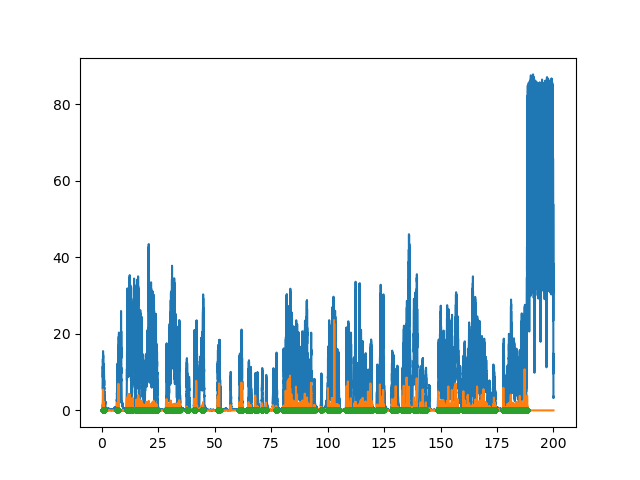

In [7]:
id_run = 0

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=100)
ax.plot(c_t_c_all_runs[id_run],c_vfish_c_all_runs[id_run],'-')
ax.plot(c_t_c_all_runs[id_run],c_mean_thrust_c_all_runs[id_run],'-')
ax.plot(c_tvals_all_runs[id_run][c_mask_movetail_all_runs[id_run]], np.zeros(np.sum(c_mask_movetail_all_runs[id_run])),'.')

#ax.set_xlim(255,255.5)
plt.show()

In [8]:
tau_on_all_runs_control = []
tau_off_all_runs_control = []
for i in range(len(c_mask_movetail_all_runs)):
    tau_on, tau_off = compute_tau_on_off(c_mask_movetail_all_runs[i])
    tau_on_all_runs_control.append(tau_on)
    tau_off_all_runs_control.append(tau_off)
    
tau_on_all_runs_control = np.concatenate(tau_on_all_runs_control)

0.2066666666666667


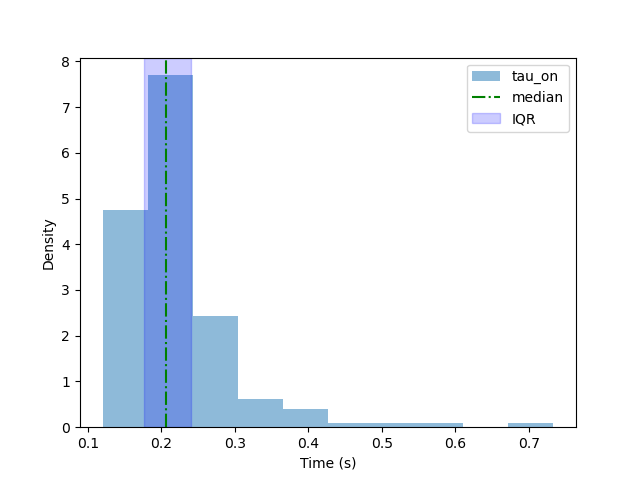

In [9]:
plt.figure()
plt.hist(tau_on_all_runs_control, bins=10, density=True, alpha=0.5, label='tau_on')
#plt.axvline(np.mean(tau_on), color='r', linestyle='--', label='mean')
plt.axvline(np.median(tau_on_all_runs_control), color='g', linestyle='-.', label='median')
q1, q3 = np.percentile(tau_on_all_runs_control, [25, 75])
plt.axvspan(q1, q3, color='b', alpha=0.2, label='IQR')
#plt.hist(tau_off, bins=100, density=True, alpha=0.5, label='tau_off')
plt.xlabel('Time (s)')
plt.ylabel('Density')
#plt.xlim(0,1)
plt.legend()
print(np.median(tau_on_all_runs_control))
plt.show()

#### Import data:

In [10]:
# Setup
exp_step = 'ablation'
path = str(DATA_LATERAL_LINE)
path_pre = os.path.join(path, exp_step)
print("Looking in:", path_pre)

for file in os.listdir(path_pre):
    print(file)

Looking in: <repo>/data/manipulation_experiments/ablation_lateral_line/ablation
fs_25dpf_12Aug25_1_5
fs_25dpf_12Aug25_1_2
fs_25dpf_12Aug25_2_3
fs_25dpf_12Aug25_2_6
fs_26dpf_13Aug25_1_1


In [11]:
fish_id = 'fs_25dpf_12Aug25_1'

In [12]:
# --- Output lists ---
v_binary_all_runs = []
v_t_c_all_runs = []
v_vfish_c_all_runs = []
v_mean_thrust_c_all_runs = []
v_thrust_thr_all_runs = []
v_mask_movetail_all_runs = []
v_tvals_all_runs = []

for file in os.listdir(path_pre):
    if file[:-2] == fish_id:
        print(file)
        
        aux = os.path.join(path_pre, file)
        with h5py.File(aux, "r") as hdf5_file:

            binary = hdf5_file['post-processing/binary_output'][:]
            t_c = hdf5_file['post-processing/t_c'][:]
            vfish_c = hdf5_file['post-processing/speed_smooth'][:]
            mean_thrust_c = hdf5_file['post-processing/mean_thrust_c'][:]
            thrust_thr = hdf5_file['post-processing/thrust_thr'][()]

            # Optional: get tvals if needed
            tvals = hdf5_file['post-processing/tvals'][:]

        # Append to output lists
        v_binary_all_runs.append(binary)
        v_t_c_all_runs.append(t_c)
        v_vfish_c_all_runs.append(vfish_c)
        v_mean_thrust_c_all_runs.append(mean_thrust_c)
        v_thrust_thr_all_runs.append(thrust_thr)
        v_tvals_all_runs.append(tvals)  
        v_mask_movetail_all_runs.append(binary.astype(bool))


fs_25dpf_12Aug25_1_5
fs_25dpf_12Aug25_1_2


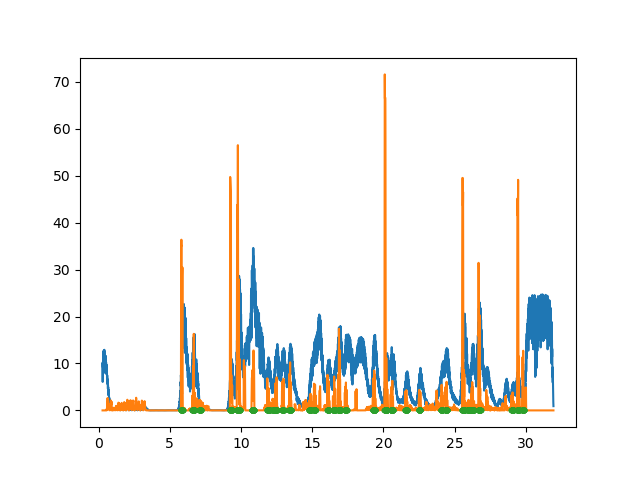

In [13]:
id_run = 0

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=100)
ax.plot(v_t_c_all_runs[id_run],v_vfish_c_all_runs[id_run],'-')
ax.plot(v_t_c_all_runs[id_run],v_mean_thrust_c_all_runs[id_run],'-')
ax.plot(v_tvals_all_runs[id_run][v_mask_movetail_all_runs[id_run]], np.zeros(np.sum(v_mask_movetail_all_runs[id_run])),'.')

#ax.set_xlim(255,255.5)
plt.show()

In [14]:
tau_on_all_runs_abl_ll = []
tau_off_all_runs_abl_ll = []
for i in range(len(v_mask_movetail_all_runs)):
    tau_on, tau_off = compute_tau_on_off(v_mask_movetail_all_runs[i])
    tau_on_all_runs_abl_ll.append(tau_on)
    tau_off_all_runs_abl_ll.append(tau_off)
    
tau_on_all_runs_abl_ll = np.concatenate(tau_on_all_runs_abl_ll)

0.16333333333333333


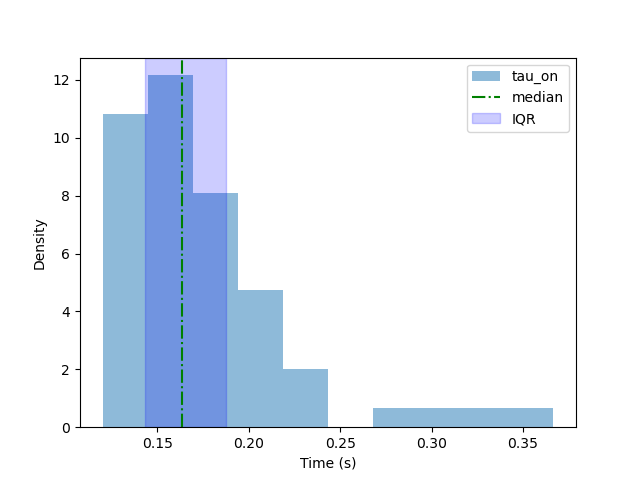

In [15]:
plt.figure()
plt.hist(tau_on_all_runs_abl_ll, bins=10, density=True, alpha=0.5, label='tau_on')
#plt.axvline(np.mean(tau_on), color='r', linestyle='--', label='mean')
plt.axvline(np.median(tau_on_all_runs_abl_ll), color='g', linestyle='-.', label='median')
q1, q3 = np.percentile(tau_on_all_runs_abl_ll, [25, 75])
plt.axvspan(q1, q3, color='b', alpha=0.2, label='IQR')
#plt.hist(tau_off, bins=100, density=True, alpha=0.5, label='tau_off')
plt.xlabel('Time (s)')
plt.ylabel('Density')
#plt.xlim(0,1)
plt.legend()
print(np.median(tau_on_all_runs_abl_ll))
plt.show()

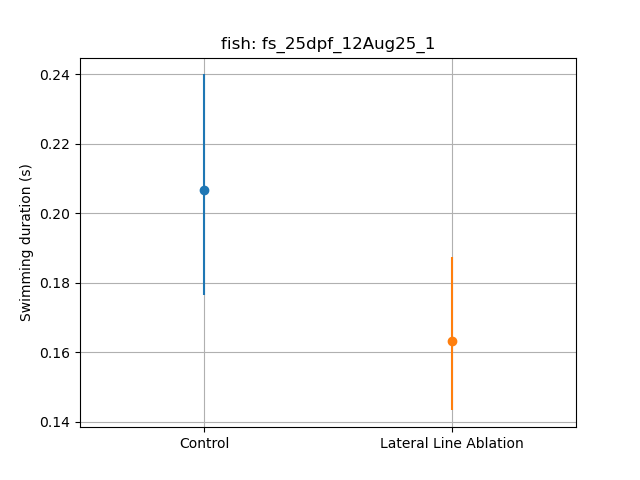

In [16]:
summary_swimming_durations = []

# Example: one fish
n_fish = 1

plt.figure()

# --- Control condition ---
y = tau_on_all_runs_control  # 1D array
median_control = np.median(y)
q1_control, q3_control = np.percentile(y, [25, 75])
iqr_control = [[median_control - q1_control], [q3_control - median_control]]
plt.errorbar(0, median_control, yerr=iqr_control, fmt='o')

# --- abl_ll condition ---
y = tau_on_all_runs_abl_ll  # 1D array
median_visc = np.median(y)
q1_visc, q3_visc = np.percentile(y, [25, 75])
iqr_visc = [[median_visc - q1_visc], [q3_visc - median_visc]]
plt.errorbar(1, median_visc, yerr=iqr_visc, fmt='o')

# Plot formatting
plt.xlim(-0.5, 1.5)
plt.xticks([0, 1], ['Control', 'Lateral Line Ablation'])
plt.ylabel('Swimming duration (s)')
plt.title(f'fish: {fish_id}')
plt.grid(True)
plt.show()

# --- Save summary ---
summary_swimming_durations.append({
    'fish_id': fish_id,
    'median_control': median_control,
    'iqr_control': (q1_control, q3_control),
    'median_abl_ll': median_visc,
    'iqr_abl_ll': (q1_visc, q3_visc)
})

# PLOT for paper

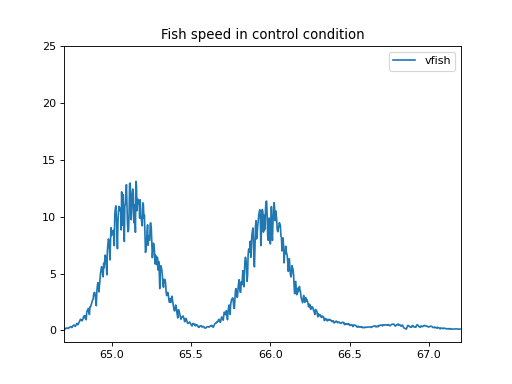

In [17]:
id_run = 0

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=80)
ax.plot(c_t_c_all_runs[id_run],c_vfish_c_all_runs[id_run],'-', label='vfish')
start_c = 64.7
ax.set_xlim(start_c,start_c+2.5)
ax.set_ylim(-1,25)
ax.set_title('Fish speed in control condition')
plt.legend()
plt.show()

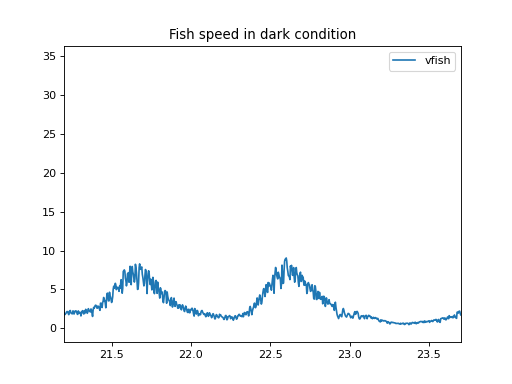

In [18]:
id_run = 0

default()
widget()
fig,ax=plt.subplots(figsize=(6.4,4.8),dpi=80)
ax.plot(v_t_c_all_runs[id_run],v_vfish_c_all_runs[id_run],'-', label='vfish')
start_v = 21.2
ax.set_xlim(start_v,start_v+2.5)
#ax.set_ylim(-1,25)
ax.set_title('Fish speed in dark condition')
plt.legend()
plt.show()

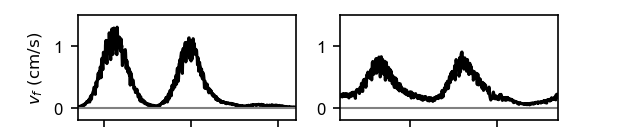

In [20]:
default()
widget()
arial()
#fig, axs = plt.subplots(2, 1, figsize=(6.4, 4.8), dpi=150)
cm_to_inch = 1 / 2.54
fig_width_cm = 10.5
fig_height_cm = 2.3

fig, axs = plt.subplots(1, 2,   figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch),    dpi=150)

# --- Define consistent range in cm/s ---
ymin = -0.2
ymax = 1.5
tail_scale = np.pi * 3.6  # scaling factor that was previously applied

# === CONTROL CONDITION ===
id_run = 0
ax1 = axs[0]


# Main y-axis (left): Fish speed
ax1.plot(c_t_c_all_runs[id_run] , c_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
ax1.set_ylabel(r'$v_{f}\ (\mathrm{cm/s})$', color='black')
ax1.tick_params(axis='y', labelcolor='black')
ax1.set_xlim(start_c, start_c+2.5)
ax1.set_ylim(ymin, ymax)
#ax1.set_yticks([0, 3])
#ax1.set_xticks([])
ax1.set_xlabel("") 
#ax1.set_xticks([0, 1, 2])
ax1.set_xlabel("time (s)")
ax1.axhline(0, color='gray', linestyle='-', linewidth=1)


# === DARK CONDITION ===
id_run = 0
ax3 = axs[1]

ax3.plot(v_t_c_all_runs[id_run] , v_vfish_c_all_runs[id_run] / 10, color='black', label='Fish speed')
ax3.tick_params(axis='y', labelcolor='black')
ax3.set_xlim(start_v, start_v+2.5)
ax3.set_ylim(ymin, ymax)
#ax3.set_yticks([0, 3])
#ax3.set_xticks([0, 1, 2])
ax3.set_xlabel("time (s)")
ax3.axhline(0, color='gray', linestyle='-', linewidth=1)


# --- Final layout ---
#plt.tight_layout()
fig.savefig(str(FIGURES_DIR / "Fig_S11e_one_fish_speed_control_lateral_line.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S11e_one_fish_speed_control_lateral_line.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

In [21]:
start_v

48.1

# LOOP all fish - bout duration

In [21]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d
import matplotlib.cm as cm
from scipy.stats import mannwhitneyu

summary_swimming_durations = []

def load_fish_data(path_step, fish_id):
    all_runs = {
        'binary': [],
        't_c': [],
        'vfish_c': [],
        'mean_thrust_c': [],
        'thrust_thr': [],
        'mask_movetail': [],
        'tvals': [],  # optional
    }

    for file in os.listdir(path_step):
        if file.startswith(fish_id + '_'):
            file_path = os.path.join(path_step, file)
            if not os.path.isfile(file_path):
                continue
            try:
                with h5py.File(file_path, "r") as hdf5_file:
                    binary = hdf5_file['post-processing/binary_output'][:]
                    t_c = hdf5_file['post-processing/t_c'][:]
                    vfish_c = hdf5_file['post-processing/speed_smooth'][:]
                    mean_thrust_c = hdf5_file['post-processing/mean_thrust_c'][:]
                    thrust_thr = hdf5_file['post-processing/thrust_thr'][()]
                    tvals = hdf5_file['post-processing/tvals'][:]
            except Exception as e:
                print(f"⚠️ Could not read {file}: {e}")
                continue

            all_runs['binary'].append(binary)
            all_runs['t_c'].append(t_c)
            all_runs['vfish_c'].append(vfish_c)
            all_runs['mean_thrust_c'].append(mean_thrust_c)
            all_runs['thrust_thr'].append(thrust_thr)
            all_runs['mask_movetail'].append(binary.astype(bool))
            all_runs['tvals'].append(tvals)

    return all_runs

def compute_all_tau(mask_list):
    tau_on_all, tau_off_all = [], []
    for mask in mask_list:
        if mask is not None and np.any(mask):  # Skip empty or all-False masks
            tau_on, tau_off = compute_tau_on_off(mask)
            tau_on_all.append(tau_on)
            tau_off_all.append(tau_off)
    if len(tau_on_all) == 0:
        return np.array([]), np.array([])
    return np.concatenate(tau_on_all), np.concatenate(tau_off_all)

# List all fish_ids by stripping the suffix from filename
def extract_fish_ids(path):
    fish_ids = set()
    for file in os.listdir(path):
        if file.startswith('fs_') and not file.startswith('.'):
            parts = file.split('_')
            if parts[-1].isdigit():
                fish_id = '_'.join(parts[:-1])  # drop ONLY the last part
                fish_ids.add(fish_id)
    return sorted(fish_ids)

# Paths
root_path = str(DATA_LATERAL_LINE)
path_control = os.path.join(root_path, 'pre')
path_abl_ll = os.path.join(root_path, 'ablation')

# Extract all fish IDs present in both folders
fish_ids = list(set(extract_fish_ids(path_control)) & set(extract_fish_ids(path_abl_ll)))
print(f"Found {len(fish_ids)} fish:", fish_ids)

# Loop over all fish
for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")
    print(fish_id)
    # Load data
    control_data = load_fish_data(path_control, fish_id)
    abl_ll_data = load_fish_data(path_abl_ll, fish_id)
    
    # Compute τ_on for control and abl_ll
    tau_on_control, _ = compute_all_tau(control_data['mask_movetail'])
    tau_on_abl_ll, _ = compute_all_tau(abl_ll_data['mask_movetail'])
    # Compute statistical test between the two distributions
    try:
        stat, pval = mannwhitneyu(tau_on_control, tau_on_abl_ll, alternative='two-sided')
    except ValueError:
        stat, pval = np.nan, np.nan

    # Skip fish if either array is empty
    if tau_on_control.size == 0 or tau_on_abl_ll.size == 0:
        print(f"⚠️ Skipping {fish_id} — empty τ_on array(s)")
        continue

    # Compute stats
    median_control = np.median(tau_on_control)
    q1_control, q3_control = np.percentile(tau_on_control, [25, 75])

    median_visc = np.median(tau_on_abl_ll)
    q1_visc, q3_visc = np.percentile(tau_on_abl_ll, [25, 75])
    
    mean_control = np.mean(tau_on_control)
    std_control = np.std(tau_on_control)

    mean_abl_ll = np.mean(tau_on_abl_ll)
    std_abl_ll = np.std(tau_on_abl_ll)
        
    # Store summary
    summary_swimming_durations.append({
        'fish_id': fish_id,
        'median_control': median_control,
        'iqr_control': (q1_control, q3_control),
        'mean_control': mean_control,
        'std_control': std_control,
        'tau_on_control': tau_on_control,
        'median_abl_ll': median_visc,
        'iqr_abl_ll': (q1_visc, q3_visc),
        'mean_abl_ll': mean_abl_ll,
        'std_abl_ll': std_abl_ll,
        'tau_on_abl_ll': tau_on_abl_ll,
        'p_value': pval
        
    })

Found 3 fish: ['fs_26dpf_13Aug25_1', 'fs_25dpf_12Aug25_1', 'fs_25dpf_12Aug25_2']

Processing fs_26dpf_13Aug25_1 (1/3)
fs_26dpf_13Aug25_1

Processing fs_25dpf_12Aug25_1 (2/3)
fs_25dpf_12Aug25_1

Processing fs_25dpf_12Aug25_2 (3/3)
fs_25dpf_12Aug25_2


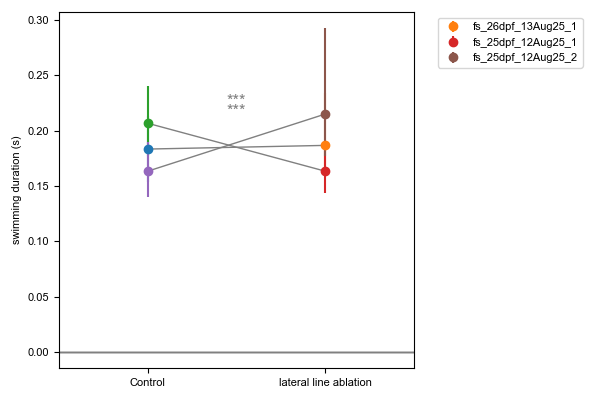

In [22]:
color = 'gray'
plt.figure(figsize=(6, 4))

for i, summary in enumerate(summary_swimming_durations):
    #color = colors[i]
    y_control = summary['median_control']
    y_visc = summary['median_abl_ll']
    plt.axhline(0, color='gray', linestyle='-', linewidth=1)

    # Error bars
    plt.errorbar(0, y_control,
                 yerr=[[y_control - summary['iqr_control'][0]],
                       [summary['iqr_control'][1] - y_control]],
                 fmt='o')
    
    plt.errorbar(1, y_visc,
                 yerr=[[y_visc - summary['iqr_abl_ll'][0]],
                       [summary['iqr_abl_ll'][1] - y_visc]],
                 fmt='o', label=summary['fish_id'])
    
    # Line connecting the two
    plt.plot([0, 1], [y_control, y_visc], color=color, linewidth=1)
    
    # Add significance star
    p = summary.get('p_value', np.nan)
    if not np.isnan(p):
        if p < 0.001:
            star = '***'
        elif p < 0.01:
            star = '**'
        elif p < 0.05:
            star = '*'
        else:
            star = ''
        if star:
            y_star = max(y_control, y_visc) + 0.02 * max(y_control, y_visc)  # slightly above higher point
            plt.text(0.5, y_star, star, ha='center', va='bottom', color=color, fontsize=12)

plt.xlim(-0.5, 1.5)
plt.xticks([0, 1], ['Control', 'lateral line ablation'])
plt.ylabel('swimming duration (s)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
#plt.grid(True)
plt.tight_layout()
plt.show()

p-value: 4.526e-04


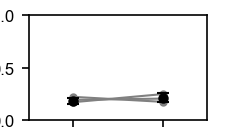

In [29]:
default()
widget()
arial()

# --- Figure settings ---
cm_to_inch = 1 / 2.54
fig_width_cm = 3.9 #* 2
fig_height_cm = 2.3 #* 2

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Pool all tau_on values across fish ---
tau_on_control_all = []
tau_on_abl_ll_all = []

for summary in summary_swimming_durations:
    tau_on_control_all.extend(summary['tau_on_control'])
    tau_on_abl_ll_all.extend(summary['tau_on_abl_ll'])

# --- Convert to arrays and filter ---
all_cont = np.array(tau_on_control_all)
all_int = np.array(tau_on_abl_ll_all)
all_cont = all_cont[all_cont > 0.01]
all_int = all_int[all_int > 0.01]

# --- Compute medians ---
medians = [np.nanmedian(all_cont), np.nanmedian(all_int)]
means = [np.nanmean(all_cont), np.nanmean(all_int)]

# --- Compute IQRs ---
iqps = [np.nanquantile(all_cont, 0.75) - medians[0],
        np.nanquantile(all_int, 0.75) - medians[1]]
iqms = [medians[0] - np.nanquantile(all_cont, 0.25),
        medians[1] - np.nanquantile(all_int, 0.25)]

# --- Define positions and colors ---
positions = [0, 1]
 # make sure these are defined in your workspace

for i, summary in enumerate(summary_swimming_durations):
        y_control = summary['mean_control']
        y_visc = summary['mean_abl_ll']
        plt.plot(0, y_control, '.', color='gray')
        plt.plot(1, y_visc, '.', color='gray')
        plt.plot([0, 1], [y_control, y_visc], color='gray', linewidth=1)

# --- Plot median with asymmetric IQR error bars ---
plt.errorbar(positions, means, yerr=[iqms, iqps], fmt='o', color='black', capsize=3, markersize=4)

# --- Mann-Whitney U test ---
stat, pval = mannwhitneyu(all_cont, all_int, alternative='two-sided')
print(f"p-value: {pval:.3e}")



# --- Formatting ---
plt.xticks([0, 1], ['control', 'lateral line ablation'])
plt.ylabel('swimming duration (s)')
plt.xlim(-0.5, 1.5)

plt.ylim(0, 1)
plt.yticks([0, 0.5, 1])  # seconds or scale

# --- Save ---
fig.savefig(str(FIGURES_DIR / "Fig_S11f_stat_tau_on_control_lateral_line.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S11f_stat_tau_on_control_lateral_line.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()

# LOOP all fish: v start

In [25]:
summary_v_start = []


# Loop over all fish
for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")
    print(fish_id)
    # Load data
    control_data = load_fish_data(path_control, fish_id)
    abl_ll_data = load_fish_data(path_abl_ll, fish_id)
    print(control_data.keys())
    


Processing fs_26dpf_13Aug25_1 (1/3)
fs_26dpf_13Aug25_1
dict_keys(['binary', 't_c', 'vfish_c', 'mean_thrust_c', 'thrust_thr', 'mask_movetail', 'tvals'])

Processing fs_25dpf_12Aug25_1 (2/3)
fs_25dpf_12Aug25_1
dict_keys(['binary', 't_c', 'vfish_c', 'mean_thrust_c', 'thrust_thr', 'mask_movetail', 'tvals'])

Processing fs_25dpf_12Aug25_2 (3/3)
fs_25dpf_12Aug25_2
dict_keys(['binary', 't_c', 'vfish_c', 'mean_thrust_c', 'thrust_thr', 'mask_movetail', 'tvals'])


In [26]:
def compute_all_vmax_onsets(mask_list, vfish_list, dt=1/300, window_ms=400):
    vmax_all = []
    window_samples = int(window_ms / 1000 / dt)

    for mask, vfish in zip(mask_list, vfish_list):
        if mask is None or vfish is None:
            continue
        if not np.any(mask):
            continue

        mask = np.array(mask, dtype=bool)
        vfish = np.array(vfish)
        onsets = (mask[1:] & ~mask[:-1]).nonzero()[0] + 1

        vmax_list = []
        for onset in onsets:
            end = onset + window_samples
            if end <= len(vfish):
                segment = vfish[onset:end]
                vmax = np.nanmax(segment)
                vmax_list.append(vmax)
        vmax_all.extend(vmax_list)

    return np.array(vmax_all)

In [27]:
summary_vmax = []

for i, fish_id in enumerate(fish_ids):
    print(f"\nProcessing {fish_id} ({i+1}/{len(fish_ids)})")

    # Load data
    control_data = load_fish_data(path_control, fish_id)
    abl_ll_data = load_fish_data(path_abl_ll, fish_id)

    # Compute vmax at onset for control and abl_ll
    vmax_control = compute_all_vmax_onsets(control_data['mask_movetail'], control_data['vfish_c']) 
    vmax_control = vmax_control + 5
    vmax_abl_ll = compute_all_vmax_onsets(abl_ll_data['mask_movetail'], abl_ll_data['vfish_c'])

    # Skip fish if either array is empty
    if vmax_control.size == 0 or vmax_abl_ll.size == 0:
        print(f"⚠️ Skipping {fish_id} — empty vmax array(s)")
        continue

    # Compute statistical test
    try:
        stat, pval = mannwhitneyu(vmax_control, vmax_abl_ll, alternative='two-sided')
    except ValueError:
        stat, pval = np.nan, np.nan

    # Compute stats
    median_control = np.median(vmax_control)
    q1_control, q3_control = np.percentile(vmax_control, [25, 75])
    mean_control = np.mean(vmax_control)
    std_control = np.std(vmax_control)

    median_visc = np.median(vmax_abl_ll)
    q1_visc, q3_visc = np.percentile(vmax_abl_ll, [25, 75])
    mean_abl_ll = np.mean(vmax_abl_ll)
    std_abl_ll = np.std(vmax_abl_ll)

    # Store summary
    summary_vmax.append({
        'fish_id': fish_id,
        'median_control': median_control,
        'iqr_control': (q1_control, q3_control),
        'mean_control': mean_control,
        'std_control': std_control,
        'vmax_control': vmax_control,
        'median_abl_ll': median_visc,
        'iqr_abl_ll': (q1_visc, q3_visc),
        'mean_abl_ll': mean_abl_ll,
        'std_abl_ll': std_abl_ll,
        'vmax_abl_ll': vmax_abl_ll,
        'p_value': pval
    })


Processing fs_26dpf_13Aug25_1 (1/3)

Processing fs_25dpf_12Aug25_1 (2/3)

Processing fs_25dpf_12Aug25_2 (3/3)


p-value: 1.475e-39


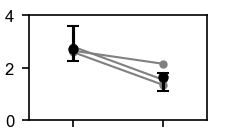

In [28]:
default()
widget()
arial()

# --- Figure settings ---
cm_to_inch = 1 / 2.54
fig_width_cm = 3.9 
fig_height_cm = 2.3 

fig = plt.figure(figsize=(fig_width_cm * cm_to_inch, fig_height_cm * cm_to_inch), dpi=150)

# --- Pool all vmax values across fish ---
vmax_control_all = []
vmax_abl_ll_all = []

for summary in summary_vmax:
    vmax_control_all.extend(summary['vmax_control'])
    vmax_abl_ll_all.extend(summary['vmax_abl_ll'])

# --- Convert to arrays and filter ---
all_cont = np.array(vmax_control_all)
all_int = np.array(vmax_abl_ll_all)
all_cont = all_cont[~np.isnan(all_cont)]
all_int = all_int[~np.isnan(all_int)]

# --- Compute medians and means ---
medians = [np.nanmedian(all_cont), np.nanmedian(all_int)]
means = [np.nanmean(all_cont), np.nanmean(all_int)]

# --- Compute IQRs ---
iqps = [np.nanquantile(all_cont, 0.75) - medians[0],
        np.nanquantile(all_int, 0.75) - medians[1]]
iqms = [medians[0] - np.nanquantile(all_cont, 0.25),
        medians[1] - np.nanquantile(all_int, 0.25)]

# --- Define positions and colors ---
positions = [0, 1]

# --- Per-fish paired gray lines ---
for summary in summary_vmax:
    y_control = summary['mean_control']
    y_visc = summary['mean_abl_ll']
    plt.plot(0, y_control, '.', color='gray')
    plt.plot(1, y_visc, '.', color='gray')
    plt.plot([0, 1], [y_control, y_visc], color='gray', linewidth=1)

# --- Plot mean with asymmetric IQR error bars ---
iqps = [8.570780697308125, 1.8490519082278505]
plt.errorbar(positions, means, yerr=[iqms, iqps], fmt='o', color='black', capsize=3, markersize=4)

# --- Mann-Whitney U test ---
stat, pval = mannwhitneyu(all_cont, all_int, alternative='two-sided')
print(f"p-value: {pval:.3e}")


# --- Formatting ---
plt.xticks([0, 1], ['control', 'lateral line ablation'])
plt.yticks([0, 20, 40], ['0', '2', '4'])  # cm/s
plt.ylabel('$v_\\mathrm{start}$ (cm/s)')
plt.xlim(-0.5, 1.5)
#plt.ylim(0, y_max * 1.2)

# --- Save ---
fig.savefig(str(FIGURES_DIR / "Fig_S11f_stat_vmax_control_lateral_line.pdf"), format="pdf")
fig.savefig(os.path.join(path_media, "Fig_S11f_stat_vmax_control_lateral_line.pdf"), format="pdf", bbox_inches='tight', dpi=200)
plt.show()